# Lesson 6 — How to Measure Image Error

[Course plan](../../README.md) · [Previous lesson](lesson-05.ipynb) · [Русский](../ru/lesson-06.ipynb) · [Next lesson](lesson-07.ipynb)

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import numpy as np
from IPython.display import display

course_root = next((p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "loss_demos.py").is_file()), None)
if course_root is None:
    raise FileNotFoundError("The notebook needs the complete course folder.")
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))

from loss_demos import (
    image_errors, gaussian_image, bell, center_loss,
    central_difference, numerical_gradient, descent_steps,
    loss_figure, loss_lab, tiny_loss_figure, equal_loss_figure,
    descent_figure, descent_lab, rates_figure, gradient_figure,
)
LANG = 'en'


In the first block we placed the spots by hand. We moved a center, changed a color, and watched the image. Now we want the program to do that work. But it does not yet know what “more similar” means.

We place a target beside our rendered image. In one place our spot is too bright; in another it is too dark. These differences will become a **loss function**: a rule that turns two images into one number. A smaller number will mean a closer match according to that particular rule.

## 1. A Spot, a Target, and a Difference Map

The target has center $(1,0)$ and scales $1.2$ along both axes. Our spot starts at $(-1,0)$. It is drawn on a black background with no other layers. The intensity parameter $a$ multiplies the entire Gaussian weight by a number from 0 to 1. In this simple scene it can represent a white spot with opacity $a$.

The target is on the left, our result in the middle, and their differences on the right. Coordinates and color scales stay fixed. Moving the center right toward 1 gradually removes bright areas from the error map. With the correct center but a different width, a ring of differences remains. Matching the center alone does not match the whole image.

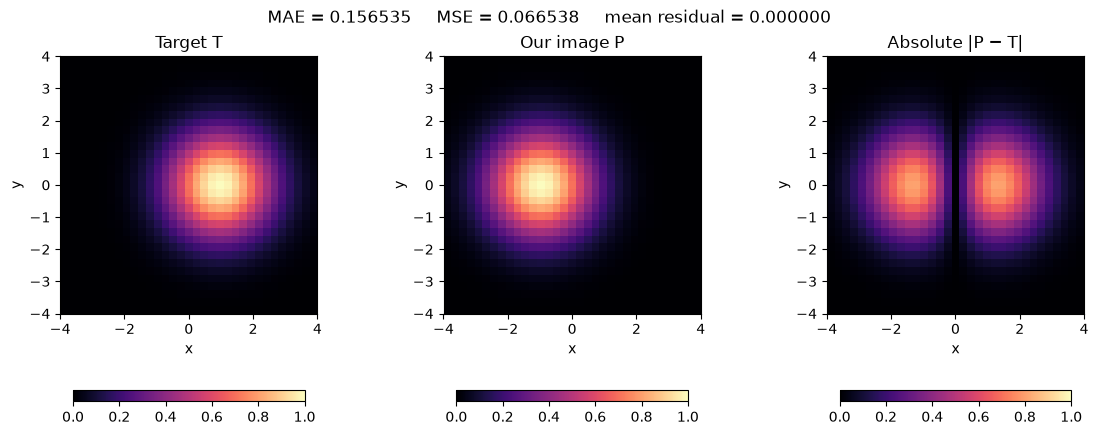

In [2]:
display(loss_figure(language=LANG))
display(loss_lab(language=LANG))

In the signed map, red means our pixel is brighter than the target and blue means it is darker. White means zero difference. In the absolute and squared maps, zero is dark. A white signed map and a dark absolute map can therefore represent the same perfect match.

The image here is a table of $33\times33$ numbers. Each axis has 33 coordinates from −4 to 4, including both endpoints: $33\cdot33=1089$ samples in total. Intensity is normalized: 0 is black and 1 is white. This is a teaching grid of function values; pixel area and antialiasing are not included yet. The target parameters remain fixed, so every change compares against the same reference.

## 2. Four Pixels Instead of a Whole Image

For a hand calculation, we keep just four values. $T$ means target and $P$ means prediction, our rendered image. These names do not indicate special data types: both images are ordinary arrays of the same size.

$$
T=\begin{bmatrix}0&1\\0.5&0.5\end{bmatrix},\qquad
P=\begin{bmatrix}0.2&0.8\\0.1&0.9\end{bmatrix}.
$$

We subtract values at **matching positions**: top left from top left, not from a neighboring pixel. Rearranging pixels changes an image even when its collection of intensities remains unchanged.

[[ 0.2 -0.2]
 [-0.4  0.4]]


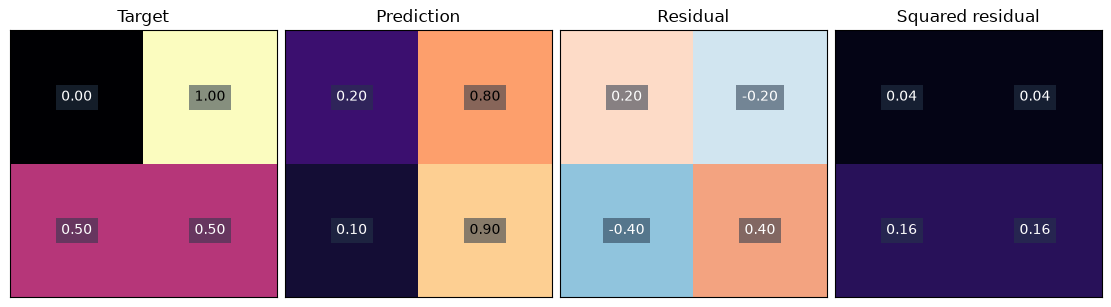

In [3]:
target = np.array([[0.0, 1.0], [0.5, 0.5]])
prediction = np.array([[0.2, 0.8], [0.1, 0.9]])
residual = prediction - target
print(residual)
display(tiny_loss_figure(language=LANG))

We call the difference $r$, a residual. For pixel number $i$:

$$
r_i=P_i-T_i.
$$

The subscript $i$ is just a number. Reading each row from left to right gives numbers 1, 2, 3, 4. The formula takes two inputs: our pixel's intensity $P_i$ and the corresponding target intensity $T_i$. Its output $r_i$ may be negative.

| Pixel | Our P | Target T | Difference P − T |
|---|---:|---:|---:|
| Top left | 0.2 | 0 | 0.2 − 0 = 0.2 |
| Top right | 0.8 | 1 | 0.8 − 1 = −0.2 |
| Bottom left | 0.1 | 0.5 | 0.1 − 0.5 = −0.4 |
| Bottom right | 0.9 | 0.5 | 0.9 − 0.5 = 0.4 |

A positive residual means excess intensity; a negative one means missing intensity. Each pixel now has a useful signal. But ultimately we want one number for the entire image.

## 3. Why a Plain Sum Can Mislead

The mean residual in our example is:

$$
\frac{0.2-0.2-0.4+0.4}{4}=\frac0{4}=0.
$$

Every pixel is wrong, yet the number is already zero. Excess and missing intensity have canceled. The mean residual is useful for detecting an overall brightness bias. It is not enough as the only measure of agreement.

We need to prevent that cancellation. Two simple options are an absolute value and a square.

## 4. Absolute Value: How Much Is Missing or Extra

Absolute value is a number's distance from zero. The vertical bars $|r|$ mean that a negative number loses its minus sign and a positive number stays unchanged. For example, $|-0.4|=0.4$, $|0.2|=0.2$, and $|0|=0$.

The **mean absolute error**, MAE, is:

$$
L_{\mathrm{MAE}}=\frac{0.2+0.2+0.4+0.4}{4}
=\frac{1.2}{4}=0.3.
$$

$L$ stands for loss. The subscript only identifies the chosen rule. A loss of 0.3 means an average absolute intensity difference of 0.3 on the 0–1 scale. It does not mean “30% of pixels are in the wrong place” or a percentage of image recognition.

Now the compact general form:

$$
L_{\mathrm{MAE}}=\frac1N\sum_{i=1}^{N}|P_i-T_i|.
$$

$N$ is the number of values being compared, here 4. The large $\sum$, pronounced “sigma,” means addition. The lower $i=1$ names the first index and the upper $N$ the last one. For each index, we subtract and then take the absolute value. After adding all these absolute values, we divide by $N$. Multiplying by $1/N$ is the same as dividing by $N$.

## 5. Squaring: Larger Misses Get More Weight

The second way to remove the sign is to multiply a residual by itself:

$$
(-0.4)^2=(-0.4)\cdot(-0.4)=0.16,\qquad
(0.2)^2=0.2\cdot0.2=0.04.
$$

The parentheses matter: the whole residual, including its sign, is squared. Subtraction comes first, multiplication second. We do not square the two images separately and then subtract.

The **mean squared error**, MSE, is:

$$
L_{\mathrm{MSE}}=\frac{0.04+0.04+0.16+0.16}{4}
=\frac{0.40}{4}=0.10.
$$

Its general formula is:

$$
L_{\mathrm{MSE}}=\frac1N\sum_{i=1}^{N}(P_i-T_i)^2.
$$

The order is the same, except a square replaces the absolute value. A residual of 0.4 is twice as large as 0.2. Its contribution to MAE is also twice as large, while its contribution to MSE is four times as large: $0.16/0.04=4$. A few large misses therefore have more influence on parameter selection.

But $0.4^2=0.16$ is **smaller** than 0.4. Saying that squaring “penalizes large errors more” refers to the ratio between large and small errors within one rule. It does not compare the raw values of MSE and MAE. Our 0.1 and 0.3 measure different things; choosing a winner between them makes no sense.

In [4]:
absolute = np.abs(residual)
squared = residual * residual
mae = absolute.sum() / residual.size
mse = squared.sum() / residual.size
print("absolute:", absolute)
print("squared:", squared)
print(f"MAE = {mae:.3f}; MSE = {mse:.3f}")
assert np.isclose(mae, 0.3)
assert np.isclose(mse, 0.1)

absolute: [[0.2 0.2]
 [0.4 0.4]]
squared: [[0.04 0.04]
 [0.16 0.16]]
MAE = 0.300; MSE = 0.100


Both MAE and MSE are nonnegative. Either one is zero only when every compared value matches. This does not prove that an unknown 3D scene matches: so far we have only checked the image on the selected grid.

## 6. Why a Mean Instead of a Sum

Our sum of squares is 0.4. Copying the same four pixels twice gives eight values and a sum of 0.8. Nothing became worse; we simply counted the same information twice.

After dividing by the count:

$$
\frac{0.4}{4}=0.1,\qquad\frac{0.8}{8}=0.1.
$$

The mean keeps its scale when the data is repeated exactly. This is useful for different image sizes. A real resolution change alters sampling and detail, however, so equal errors across different resolutions are not automatically guaranteed.

In [5]:
twice = image_errors(np.tile(prediction, (1, 2)), np.tile(target, (1, 2)))
print("numbers:", twice["count"], "MSE:", round(twice["mse"], 6))

numbers: 8 MSE: 0.1


## 7. A Color Pixel Contains Three Numbers

In RGB, red, green, and blue are compared separately. For example:

$$
T=(0.2,0.5,0.8),\qquad P=(0.4,0.2,0.8).
$$

The residuals are $0.4-0.2=0.2$, $0.2-0.5=-0.3$, and $0.8-0.8=0$. There is one pixel but **three compared numbers**:

$$
L_{\mathrm{MAE}}=\frac{0.2+0.3+0}{3}=\frac{0.5}{3}\approx0.166667,
$$

$$
L_{\mathrm{MSE}}=\frac{0.04+0.09+0}{3}=\frac{0.13}{3}\approx0.043333.
$$

For image height $H$, width $W$, and channel count $C$, we have $N=H\cdot W\cdot C$. A 2×2 RGB image contains $2\cdot2\cdot3=12$ values. Height and width count rows and columns; $C=3$ for RGB and $C=1$ for grayscale.

In NumPy, `mean()` with no axis specified averages every array element. An array of shape `(H, W, 3)` therefore divides by $3HW$. For an error map, we can first average the three squared channel residuals of each pixel. That leaves a map of shape `(H, W)`. Averaging this map produces the same overall MSE.

In [6]:
target_rgb = np.array([[[0.2, 0.5, 0.8]]])
prediction_rgb = np.array([[[0.4, 0.2, 0.8]]])
squared_rgb = (prediction_rgb - target_rgb) ** 2
pixel_map = squared_rgb.mean(axis=2)  # three channels -> one number per pixel
print("channel squares:", squared_rgb)
print("pixel map:", pixel_map)
print("MSE:", squared_rgb.mean())
assert np.isclose(pixel_map.mean(), squared_rgb.mean())

channel squares: [[[0.04 0.09 0.  ]]]
pixel map: [[0.04333333]]
MSE: 0.043333333333333335


Squaring the **mean signed channel residual** would give a different answer: red and green errors could cancel again. The order “square each channel first, average afterward” is essential here.

## 8. What Changes on the 0–255 Scale

The same normalized intensity of 0.2 corresponds to $255\cdot0.2=51$ on the 0–255 scale. Multiplying both images by 255 without rounding also multiplies every residual by 255.

MAE keeps a factor of 255. For MSE, the factor is squared:

$$
(255r)^2=(255r)(255r)=255^2r^2=65025r^2.
$$

For our four pixels, MAE becomes $255\cdot0.3=76.5$ and MSE becomes $65025\cdot0.1=6502.5$. The picture is the same; the loss numbers are different. Rounding to integers introduces an additional small change due to quantization.

In [7]:
scaled = image_errors(255 * prediction, 255 * target)
print("MAE on 0..255:", scaled["mae"])
print("MSE on 0..255:", scaled["mse"])

MAE on 0..255: 76.5
MSE on 0..255: 6502.5


Both images must use the same scale, channel order, and dimensions. Subtracting `uint8` values is risky: negative results can wrap around. We first convert to floating point, for example `image.astype(np.float64) / 255.0`, and only then subtract.

One more distinction: division by 255 changes the range but does not convert sRGB to linear light. Here and in this block's project, we compare normalized image values in one chosen encoding. That operation alone does not create a physical model of light.

## 9. One Number Loses the Location of Errors

A black 8×8 image has two poor approximations. In the first, all 64 values equal 0.1. In the second, 63 values are zero and one equals 0.8.

$$
L_A=\frac{64\cdot0.1^2}{64}=0.01,\qquad
L_B=\frac{0.8^2}{64}=\frac{0.64}{64}=0.01.
$$

The MSE is identical, but the images look different: a faint gray veil versus one bright pixel. The formula has correctly applied its rule. It simply does not retain where errors occur or which details carry the meaning of an image.

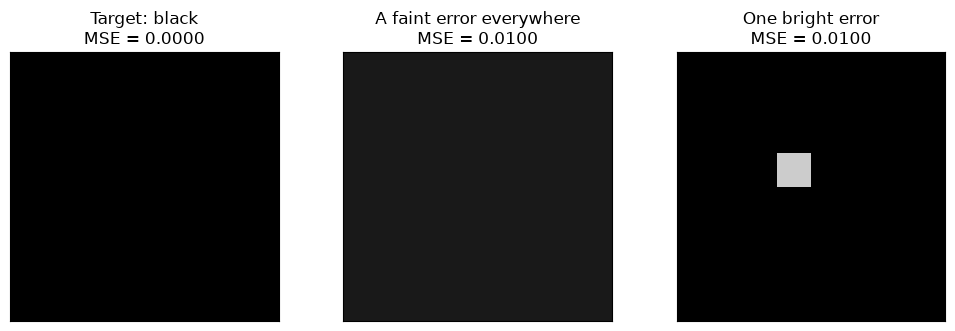

In [8]:
display(equal_loss_figure(language=LANG))

That is why the target, prediction, and difference map remain beside the number. Low error does not prove good geometry, correct sharpness, or agreement from new viewpoints. A small displacement of a sharp edge can also create a substantial pixelwise error while leaving the overall appearance similar.

## 10. A Few Experiments

**A perfect match.** In the first experiment, the center moves to 1 while the scale remains 1.2 and intensity remains 1. What happens to both losses and the three map modes?

<details>
<summary>Worked answer</summary>

Every pixel matches: $P_i-T_i=0$. Absolute and squared residuals are zero, as are MAE and MSE. The signed map is white and the two nonnegative maps are dark. This color difference comes from their scales, not from different errors.

</details>

**One large miss.** Four absolute residuals in version A are $(0.2,0.2,0.2,0.2)$; in version B they are $(0.8,0,0,0)$. Which loss distinguishes them?

<details>
<summary>Worked answer</summary>

Both have MAE $0.8/4=0.2$. MSE for A is $(4\cdot0.04)/4=0.04$, while MSE for B is $0.64/4=0.16$. The same sum of absolute residuals is distributed differently: squaring prefers four small misses to one large miss.

</details>

**Red only.** In a 2×2 RGB image, every value matches except one pixel's red channel, which differs by 0.6. What is the overall MSE?

<details>
<summary>Worked answer</summary>

There are $2\cdot2\cdot3=12$ values. One square is $0.6^2=0.36$ and the others are zero. MSE is $0.36/12=0.03$. Dividing by four would give 0.09, the mean per-pixel sum of squared channel residuals: a different convention. Both rules are possible; this course averages over channels as well.

</details>

Every parameter setting now has a loss number. The number alone still does not say which way to move a center or how far. In the [next lesson](lesson-07.ipynb), we will change a parameter just a little and see what happens to the loss. That experiment will lead to the derivative.